# 04 — Objetivo extra (opcional): YOLO de classificação com transferência de aprendizagem

- Modelo: **YOLO11n-cls** (Ultralytics) com pesos pré-treinados no ImageNet, ajustado ao TrashNet.
- Mesmas **seis classes e mesma divisão** (`splits/split.csv`); nenhuma nova divisão automática.
- Configuração escolhida pela **validação**; comparação no **mesmo teste** com a CNN obrigatória de maior F1 macro de validação.

> Requer GPU (T4) e que os notebooks 02 e 03 já tenham sido executados.

In [5]:
# Configuração do ambiente
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    # Usando force_remount=True para tentar resolver problemas de montagem anteriores
    drive.mount("/content/drive", force_remount=True)
    # Caminho da pasta trashnet-rna no seu Google Drive. Para descobrir: painel "Arquivos"
    # (ícone de pasta à esquerda) -> drive -> MyDrive -> ... -> botão direito na pasta
    # trashnet-rna -> "Copiar caminho", e cole entre as aspas abaixo.
    PROJECT_DIR = "/content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna"
    # As imagens ficam no disco do próprio Colab, que é mais rápido que o Drive.
    os.environ["TRASHNET_DATA_DIR"] = "/content/data"
else:
    PROJECT_DIR = ".."  # rodando no computador, a partir da pasta notebooks/
if not os.path.isdir(os.path.join(PROJECT_DIR, "src", "trashnet")):
    raise FileNotFoundError(f"Não encontrei o projeto em {PROJECT_DIR}. Corrija o PROJECT_DIR acima.")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
print("Projeto:", os.getcwd())

Mounted at /content/drive
Projeto: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna


In [6]:
!pip -q install "ultralytics>=8.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 12.0 MB/s eta 0:00:00


In [7]:
import shutil, time, json, re, resource
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from ultralytics import YOLO
import ultralytics
from trashnet import config as C
from trashnet import evaluate as E
from trashnet.data import download_dataset, load_split

download_dataset()
split_df = load_split()

# ---- Configuração (ajustável; registrem no artigo a escolhida pela validação) ----
YOLO_CFG = dict(model="yolo11n-cls.pt", imgsz=224, epochs=50, batch=32, patience=10,
                optimizer="AdamW", lr0=0.001, seed=C.SEED, deterministic=True)
RUN_NAME = "yolo11n_cls_224"
YOLO_DIR = C.OUTPUT_DIR / "yolo"
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Baixando https://huggingface.co/datasets/garythung/trashnet/resolve/main/dataset-resized.zip?download=true
Dataset extraído em /content/data/dataset-resized
ultralytics 8.4.178 | torch 2.11.0+cu130 | GPU: Tesla T4


## 1. Estrutura de pastas por classe com a divisão original

In [8]:
YOLO_DATA = C.DATA_DIR / "yolo_split"
if not YOLO_DATA.exists():
    for _, r in split_df.iterrows():
        dst = YOLO_DATA / r["split"] / r["label"] / r["filepath"].split("/")[-1]
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(C.DATASET_ROOT / r["filepath"], dst)
for s in ["train", "val", "test"]:
    print(s, {c: len(list((YOLO_DATA / s / c).glob("*"))) for c in C.CLASSES})

train {'glass': 348, 'paper': 416, 'cardboard': 282, 'plastic': 336, 'metal': 286, 'trash': 96}
val {'glass': 75, 'paper': 89, 'cardboard': 60, 'plastic': 72, 'metal': 61, 'trash': 21}
test {'glass': 75, 'paper': 89, 'cardboard': 61, 'plastic': 72, 'metal': 62, 'trash': 20}


## 2. Treinamento (validação na pasta `val`; o teste não é usado aqui)

In [9]:
run_dir = YOLO_DIR / RUN_NAME
if (run_dir / "weights" / "best.pt").exists():
    print("Treino já concluído — pulando. Apague a pasta para refazer:", run_dir)
    custo = json.loads((run_dir / "custo.json").read_text())
else:
    model = YOLO(YOLO_CFG["model"])
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    model.train(data=str(YOLO_DATA), imgsz=YOLO_CFG["imgsz"], epochs=YOLO_CFG["epochs"],
                batch=YOLO_CFG["batch"], patience=YOLO_CFG["patience"], optimizer=YOLO_CFG["optimizer"],
                lr0=YOLO_CFG["lr0"], seed=YOLO_CFG["seed"], deterministic=YOLO_CFG["deterministic"],
                project=str(YOLO_DIR), name=RUN_NAME, exist_ok=True, save_period=1, workers=2)
    total = time.perf_counter() - t0
    hist = pd.read_csv(run_dir / "results.csv"); hist.columns = hist.columns.str.strip()
    custo = {"tempo_total_s": round(total, 2), "epocas": int(len(hist)),
             "tempo_medio_epoca_s": round(total / len(hist), 2),
             "pico_gpu_mb": round(torch.cuda.max_memory_allocated() / 1024**2, 1) if torch.cuda.is_available() else None,
             "pico_ram_mb": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1),
             "metodo": "perf_counter em torno de model.train (inclui validação por época e salvamento "
                       "de checkpoints); RAM = ru_maxrss do processo; GPU = torch.cuda.max_memory_allocated"}
    (run_dir / "custo.json").write_text(json.dumps(custo, indent=2))
best = YOLO(run_dir / "weights" / "best.pt")
custo["parametros"] = int(sum(p.numel() for p in best.model.parameters()))
custo["tamanho_mb"] = round((run_dir / "weights" / "best.pt").stat().st_size / 1024**2, 2)
custo

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo_split, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_cls_224, nbs=64, nms=None, opset=None, optimize=False

{'tempo_total_s': 483.23,
 'epocas': 36,
 'tempo_medio_epoca_s': 13.42,
 'pico_gpu_mb': 421.9,
 'pico_ram_mb': 3447.9,
 'metodo': 'perf_counter em torno de model.train (inclui validação por época e salvamento de checkpoints); RAM = ru_maxrss do processo; GPU = torch.cuda.max_memory_allocated',
 'parametros': 1538790,
 'tamanho_mb': 3.05}

## 3. Curvas de perda e acurácia de treino e validação

O Ultralytics registra a perda de treino (com aumento de dados) e a acurácia de validação, mas não a acurácia de treino.
Por isso, os checkpoints salvos a cada época (`save_period=1`) são reavaliados, sem aumento de dados, em treino e validação.

1 0.574 0.561
2 0.768 0.741
3 0.807 0.757
4 0.856 0.791
5 0.88 0.804
6 0.885 0.817
7 0.925 0.817
8 0.92 0.841
9 0.937 0.844
10 0.961 0.82
11 0.968 0.865
12 0.955 0.865
13 0.981 0.868
14 0.983 0.889
15 0.97 0.854
16 0.977 0.868
17 0.98 0.868
18 0.991 0.894
19 0.982 0.897
20 0.951 0.831
21 0.993 0.905
22 0.993 0.886
23 0.989 0.892
24 0.996 0.894
25 0.994 0.899
26 0.998 0.918
27 0.994 0.892
28 0.999 0.886
29 0.998 0.918
30 0.999 0.894
31 0.999 0.913
32 0.999 0.918
33 1.0 0.918
34 0.999 0.91
35 0.999 0.889
36 1.0 0.91
Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_yolo_curvas.png


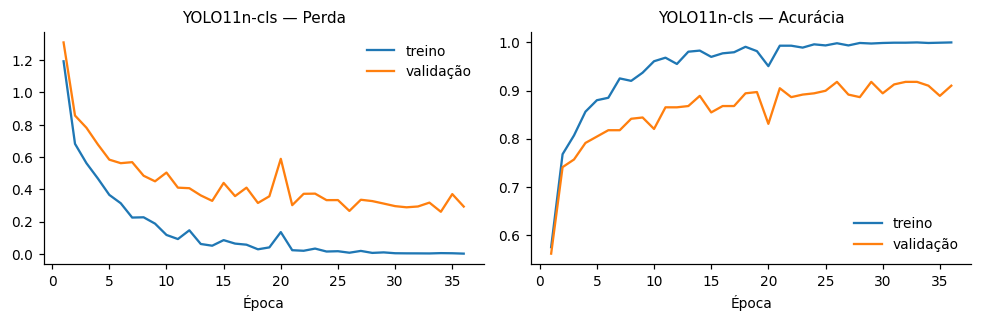

In [10]:
def avaliar_pesos(peso, split):
    m = YOLO(peso)
    part = split_df[split_df.split == split]
    paths = [str(C.DATASET_ROOT / f) for f in part["filepath"]]
    idx = {i: C.CLASS_TO_IDX[n] for i, n in m.names.items()}
    probs = np.zeros((len(paths), C.NUM_CLASSES), dtype=np.float32)
    for k in range(0, len(paths), 64):
        for j, r in enumerate(m.predict(paths[k:k + 64], imgsz=YOLO_CFG["imgsz"], verbose=False)):
            p = r.probs.data.cpu().numpy()
            for i_yolo, i_nosso in idx.items():
                probs[k + j, i_nosso] = p[i_yolo]
    y = part["label_idx"].to_numpy()
    loss = float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1)).mean())
    return probs, y, part, loss, float((probs.argmax(1) == y).mean())

curvas_csv = run_dir / "curvas_treino_validacao.csv"
if curvas_csv.exists():
    curvas = pd.read_csv(curvas_csv)
else:
    ckpts = sorted((run_dir / "weights").glob("epoch*.pt"), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))
    linhas = []
    for ep, ck in enumerate(ckpts, start=1):
        _, _, _, lt, at = avaliar_pesos(ck, "train")
        _, _, _, lv, av = avaliar_pesos(ck, "val")
        linhas.append({"epoch": ep, "loss": lt, "accuracy": at, "val_loss": lv, "val_accuracy": av})
        print(ep, round(at, 3), round(av, 3))
    curvas = pd.DataFrame(linhas); curvas.to_csv(curvas_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, (m, nome) in zip(axes, [("loss", "Perda"), ("accuracy", "Acurácia")]):
    ax.plot(curvas.epoch, curvas[m], label="treino"); ax.plot(curvas.epoch, curvas[f"val_{m}"], label="validação")
    ax.set_title(f"YOLO11n-cls — {nome}"); ax.set_xlabel("Época"); ax.legend(frameon=False)
fig.tight_layout(); E.save_fig(fig, "fig_yolo_curvas"); plt.show()

## 4. Avaliação no teste e comparação com a melhor CNN

In [11]:
def preds_df(probs, part):
    d = part[["filepath", "label", "label_idx"]].copy()
    d["pred_idx"] = probs.argmax(1); d["pred"] = [C.CLASSES[i] for i in d.pred_idx]; d["prob_pred"] = probs.max(1)
    for i, c in enumerate(C.CLASSES): d[f"prob_{c}"] = probs[:, i]
    return d

pv, _, part_v, _, _ = avaliar_pesos(run_dir / "weights" / "best.pt", "val")
pt, _, part_t, _, _ = avaliar_pesos(run_dir / "weights" / "best.pt", "test")
yolo_val, yolo_test = preds_df(pv, part_v), preds_df(pt, part_t)
(C.RESULTS_DIR / "previsoes").mkdir(parents=True, exist_ok=True)
yolo_test.to_csv(C.RESULTS_DIR / "previsoes" / "test_YOLO11n_cls.csv", index=False)

# CNN obrigatória de maior F1 macro de validação
cnns = [e for e in C.EXPERIMENTS if C.EXPERIMENTS[e]["model"] == "cnn"]
val_f1 = {e: E.global_metrics(E.predict_split(e, split_df, "val"))["f1_macro"] for e in cnns}
CNN_REF = max(val_f1, key=val_f1.get)
cnn_test = E.predict_split(CNN_REF, split_df, "test")
s = E.load_summary(CNN_REF)
print("CNN de referência:", CNN_REF, C.experiment_label(CNN_REF))

comp = pd.DataFrame([
    {"modelo": "YOLO11n-cls (pré-treinado)", "resolucao": f"{YOLO_CFG['imgsz']}×{YOLO_CFG['imgsz']}",
     "val_f1_macro": E.global_metrics(yolo_val)["f1_macro"],
     **{f"{k}_teste": v for k, v in E.global_metrics(yolo_test).items()},
     "parametros": custo["parametros"], "tamanho_mb": custo["tamanho_mb"], "epocas": custo["epocas"],
     "tempo_total_s": custo["tempo_total_s"], "tempo_medio_epoca_s": custo["tempo_medio_epoca_s"],
     "pico_ram_mb": custo["pico_ram_mb"], "pico_gpu_mb": custo["pico_gpu_mb"], "lote": YOLO_CFG["batch"]},
    {"modelo": C.experiment_label(CNN_REF), "resolucao": s["resolucao_lxa"], "val_f1_macro": val_f1[CNN_REF],
     **{f"{k}_teste": v for k, v in E.global_metrics(cnn_test).items()},
     "parametros": s["parametros"], "tamanho_mb": s["tamanho_modelo_mb"], "epocas": s["epocas_executadas"],
     "tempo_total_s": s["tempo_total_s"], "tempo_medio_epoca_s": s["tempo_medio_epoca_s"],
     "pico_ram_mb": s["pico_ram_mb"], "pico_gpu_mb": s["pico_gpu_mb"],
     "lote": s["hiperparametros_treino"]["batch_size"]},
])
comp.to_csv(C.RESULTS_DIR / "tabela_yolo_vs_cnn.csv", index=False)
comp.round(4)

CNN de referência: E6_cnn_512x384 CNN 512×384 sem pesos


,modelo,resolucao,val_f1_macro,acuracia_teste,f1_macro_teste,parametros,tamanho_mb,epocas,tempo_total_s,tempo_medio_epoca_s,pico_ram_mb,pico_gpu_mb,lote
0,YOLO11n-cls (pré-treinado),224×224,0.9045,0.9420,0.9267,1538790,3.05,36,483.23,13.42,3447.9,421.9,32
1,CNN 512×384 sem pesos,512x384,0.7271,0.7863,0.7616,405254,1.60,93,1299.10,13.94,5127.0,7969.0,32


,classe,precisao,recall,f1,suporte
0,glass,0.973,0.947,0.959,75
1,paper,0.913,0.944,0.928,89
2,cardboard,1.000,0.934,0.966,61
3,plastic,0.932,0.944,0.938,72
4,metal,0.953,0.984,0.968,62
5,trash,0.800,0.800,0.800,20


Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_yolo_vs_cnn_confusao.png


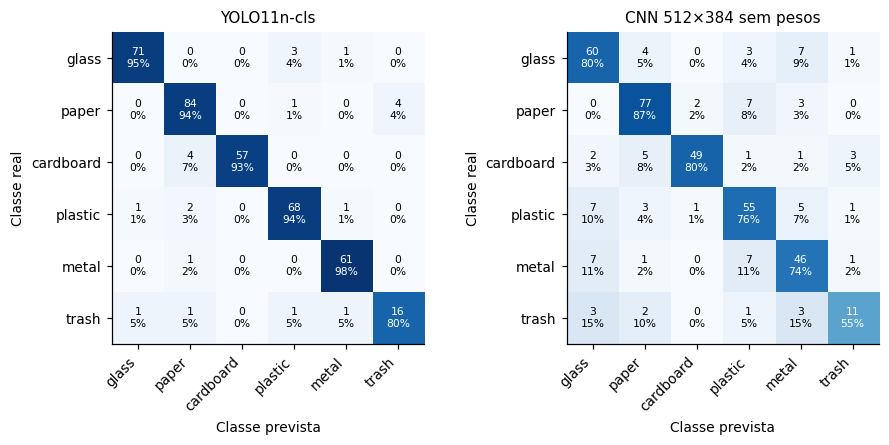

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_yolo_erros.png


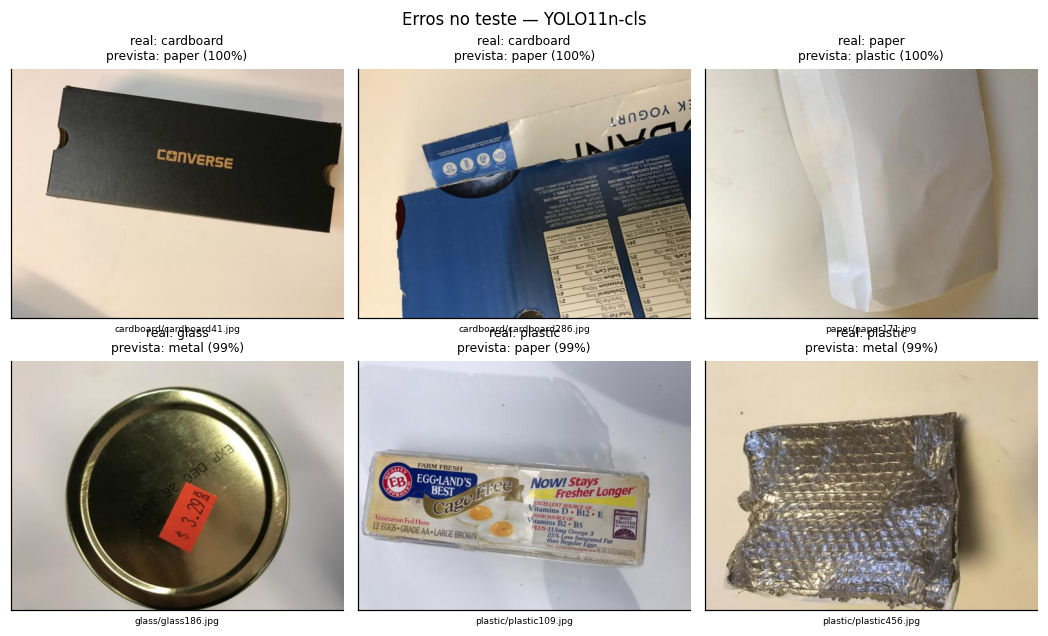

In [12]:
display(E.per_class_report(yolo_test).round(3))
fig = E.plot_confusions({"YOLO11n-cls": yolo_test, CNN_REF: cnn_test}); E.save_fig(fig, "fig_yolo_vs_cnn_confusao"); plt.show()
fig, erros_yolo = E.plot_errors(yolo_test, "Erros no teste — YOLO11n-cls", n=6)
if fig is not None: E.save_fig(fig, "fig_yolo_erros"); plt.show()

**Discussão do extra.** A análise completa está na Seção 4 do artigo ([`artigo/artigo_trashnet.pdf`](../artigo/artigo_trashnet.pdf)).
Em resumo: o YOLO11n-cls pré-treinado obteve F1 macro de teste de 0,927 (contra 0,762 da CNN E6), foi melhor em todas as
classes e treinou em 37 % do tempo da E6. A principal diferença é o pré-treinamento no ImageNet; o YOLO também usa aumento de
dados próprio e entrada menor (224×224 com recorte central). Ele sobreajustou (acurácia de 1,00 no treino e cerca de 0,91 na
validação), e 13 dos seus 22 erros também foram erros da CNN E6.